# Meridional Heat Transport

## (MOM5) 

This recipe calculates the model's meridional heat transport (MHT) using two methods based on distinct MOM5 diagnostics. The methods and the caveats associated with them are listed below:

### Method 1: Using online diagnostics

This is the recommended method. In MOM5 the meridional heat transported associated to resolved advection is given by the `temp_yflux_adv_int_z`. The heat fluxes associated to parametrised processes are provided in separate diagnostics (like `temp_yflux_gm` and `temp_yflux_ndiffuse` for the mesoscale parametrisations and `temp_yflux_submeso` for the submesoscale parametrisations).

This recipe uses ACCESS-OM2-01, which does not have mesoscale parametrisations (and therefore no `temp_yflux_gm` or `temp_yflux_ndiffuse`). We further assume the heat flux due to submesoscale parametrisation (`temp_yflux_submeso`) is small and that the bulk of the meridional heat flux is due to resolved advection `temp_yflux_adv_int_z`.

Summing `temp_yflux_adv_int_z` along a row of the model grid gives the heat transport across that row. South of 65$^\circ$N the rows are latitude circles, but further north, on the tripolar part of the grid, they are not. There we use [sectionate](https://sectionate.readthedocs.io) to compute the heat transport across true latitude circles, which also needs the zonal heat flux `temp_xflux_adv_int_z`.

### Method 2: Using surface and frazil heat fluxes

This is an alternative method that approximates the meridional heat transport from surface heat fluxes for the simulations in which the online diagnostics needed in Method 1 are not available. Note that this method relies on a steady state assumption. We use two diagnostics: `net_sfc_heating` (net surface heat flux) and `frazil_3d_int_z` which is the heat flux due to frazil formation at higher latitudes.
  
The recipe calculates the total (all basins) MHT, and it also includes comparisons to a few observational products. Basin-specific MHT can be calculated by defining relevant masks.

**Requirements:** The `conda/analysis3-26.12` (or later) module on ARE, which includes `sectionate` 0.3.5. The heat transport north of 65$^\circ$N needs `sectionate` 0.3.5 or later: earlier versions get the transports wrong where latitude circles cross the fold of the tripolar grid. Add `gdata/cj50`, `gdata/ik11` and `gdata/vk83` to the storage of your ARE session: the model output is in `cj50`, the observations in `ik11`, and we read the model's horizontal grid from `vk83`.

## Information needed to adapt to MOM6

The diagnostics for meridional heat transports are called `T_ady_2d` (from resolved advection), `T_diffy_2d` (from diffusion) and `hfds` for the surface heat flux (includes frazil contribution). North of 65$^\circ$N we also need the zonal heat transport, `T_adx_2d` (and `T_diffx_2d`). MOM6 usually saves its output on a *symmetric* grid, with one more corner than cell centre in each direction: when building the `xgcm.Grid` for `sectionate`, put the corner coordinates `xq` and `yq` at the `outer` position instead of `right`.

## MOM5 recipe

In [1]:
import intake

import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean

import xgcm
import sectionate

from dask.distributed import Client
import warnings
warnings.filterwarnings("ignore", category = FutureWarning)
warnings.filterwarnings("ignore", category = UserWarning)
warnings.filterwarnings("ignore", category = RuntimeWarning)

print(f"sectionate version {sectionate.__version__}")

sectionate version 0.3.5


Start dask cluster.

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 28
Total threads: 28,Total memory: 112.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:35205,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:36073,Total threads: 1
Dashboard: http://127.0.0.1:40159/status,Memory: 4.00 GiB
Nanny: tcp://127.0.0.1:37755,


Load ACCESS-NRI default catalog

In [3]:
catalog = intake.cat.access_nri

Define experiment of interest

In [4]:
experiment = '01deg_jra55v140_iaf_cycle3'
start_time = '2000-01-01'
end_time = '2005-12-31'

We are now ready to load the data to start our analysis. We load `temp_yflux_adv_int_z`. For this example, we have chosen to use 6 years of output.

## Method 1: Using online diagnostics

In [5]:
ds_adv = catalog[experiment].search(variable = ['temp_yflux_adv_int_z'], frequency='1mon').to_dask(xarray_open_kwargs={"decode_timedelta": True})
ds_adv = ds_adv['temp_yflux_adv_int_z'].sel(time=slice(start_time, end_time))
ds_adv

<xarray.DataArray 'temp_yflux_adv_int_z' (time: 72, yu_ocean: 2700,
                                          xt_ocean: 3600)> Size: 3GB
dask.array<getitem, shape=(72, 2700, 3600), dtype=float32, chunksize=(3, 2700, 3600), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) datetime64[ns] 576B 2000-01-16T12:00:00 ... 2005-12-16T1...
  * yu_ocean  (yu_ocean) float64 22kB -81.09 -81.05 -81.0 ... 89.92 89.96 90.0
  * xt_ocean  (xt_ocean) float64 29kB -279.9 -279.8 -279.7 ... 79.75 79.85 79.95
Attributes:
    long_name:      z-integral of cp*rho*dxt*v*temp
    units:          Watts
    valid_range:    [-1.e+18  1.e+18]
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT

We compute the mean across `time`, sum over all longitudes, and convert from Watts (W) to petawatts (PW, 1 PW = 10$^{15}$ W).

In [6]:
MHT_method_1 = (ds_adv.mean('time').sum('xt_ocean') / 1e15).load()
MHT_method_1.attrs = {"long_name": "northward heat transport", "units": "PW"}

### North of 65$^\circ$N: the grid rows are not latitude circles

ACCESS-OM2 uses a tripolar grid. South of 65$^\circ$N it is a regular latitude--longitude (Mercator) grid, but further north its rows bend around two poles over land, in Canada and Siberia, so they are no longer latitude circles. To see this we need the true longitude and latitude of the grid points. The model saves them (e.g., `geolon_c` and `geolat_c`), but with NaNs over the land tiles that weren't run, so instead we read them from the model's horizontal grid file `ocean_hgrid.nc`. That file describes a *supergrid* with twice the model's resolution: the corners of the model's cells are at its even indices, and the cell centres and the centres of the cell faces at its odd ones.

We also load the zonal heat flux `temp_xflux_adv_int_z`, which we'll need below.

In [7]:
ds_adv_x = catalog[experiment].search(variable = ['temp_xflux_adv_int_z'], frequency='1mon').to_dask(xarray_open_kwargs={"decode_timedelta": True})
ds_adv_x = ds_adv_x['temp_xflux_adv_int_z'].sel(time=slice(start_time, end_time))

hgrid = xr.open_dataset('/g/data/vk83/experiments/inputs/access-om2/ocean/grids/mosaic/global.01deg/2020.05.30/ocean_hgrid.nc')
x, y = hgrid.x.values, hgrid.y.values

# MOM5 puts the corner (xu_ocean, yu_ocean) to the north-east of the cell centre (xt_ocean, yt_ocean).
grid_coords = xr.Dataset(coords={
    "xt_ocean": ds_adv.xt_ocean, "yt_ocean": ds_adv_x.yt_ocean,
    "xu_ocean": ds_adv_x.xu_ocean, "yu_ocean": ds_adv.yu_ocean,
    "geolon_t": (("yt_ocean", "xt_ocean"), x[1::2, 1::2]),  # cell centres
    "geolat_t": (("yt_ocean", "xt_ocean"), y[1::2, 1::2]),
    "geolon_c": (("yu_ocean", "xu_ocean"), x[2::2, 2::2]),  # cell corners
    "geolat_c": (("yu_ocean", "xu_ocean"), y[2::2, 2::2]),
    "geolon_u": (("yt_ocean", "xu_ocean"), x[1::2, 2::2]),  # centres of the east faces
    "geolat_u": (("yt_ocean", "xu_ocean"), y[1::2, 2::2]),
    "geolon_v": (("yu_ocean", "xt_ocean"), x[2::2, 1::2]),  # centres of the north faces
    "geolat_v": (("yu_ocean", "xt_ocean"), y[2::2, 1::2]),
})

Let's look at the true latitude along a few rows of cell corners:

In [8]:
for row in [55, 60, 65, 70, 75, 80, 85]:
    geolat_row = grid_coords.geolat_c.sel(yu_ocean=row, method="nearest")
    print(f"row yu_ocean = {float(geolat_row.yu_ocean):6.2f}: true latitude from {float(geolat_row.min()):6.2f} to {float(geolat_row.max()):6.2f} °N")

row yu_ocean =  54.98: true latitude from  54.98 to  54.98 °N
row yu_ocean =  60.02: true latitude from  60.02 to  60.02 °N
row yu_ocean =  64.99: true latitude from  64.99 to  64.99 °N
row yu_ocean =  70.02: true latitude from  64.99 to  70.02 °N
row yu_ocean =  75.01: true latitude from  64.99 to  75.01 °N
row yu_ocean =  79.99: true latitude from  64.99 to  79.99 °N
row yu_ocean =  85.02: true latitude from  64.99 to  85.02 °N


Up to 65$^\circ$N each row lies on a latitude circle. Further north, every row starts at 65$^\circ$N, at the grid's poles, and reaches the latitude given by `yu_ocean` only halfway between them. So north of 65$^\circ$N, `MHT_method_1` is the heat transport across a grid row, which is a closed curve around the Arctic, but not the latitude circle we label it with.

### Heat transport across latitude circles with `sectionate`

On the model grid, the best we can do to follow a latitude circle, e.g., 75$^\circ$N, is a closed path along the edges of the grid cells, as a staircase. The heat transport across that path is the sum, over the cell faces that make up the staircase, of the heat transport through each face: `temp_xflux_adv_int_z` for the east and west faces and `temp_yflux_adv_int_z` for the north and south faces, each with a sign that says whether the heat goes into or out of the region north of the path. We don't need to rotate any vectors to the north: these diagnostics are already the heat transports through the cell faces.

[sectionate](https://sectionate.readthedocs.io) does exactly this. `sectionate.grid_section` finds the staircase of cell corners that best follows a path through given points, and `sectionate.convergent_transport` sums the transport through the faces along it. It needs an `xgcm.Grid` that describes the model grid. MOM5 uses a B-grid for its velocities, but its tracer fluxes are on the faces of the tracer cells, as on a C-grid. MOM5 saves its output on a *non-symmetric* grid: there are as many corners as cell centres in each direction, and each corner is to the north-east of its cell centre, i.e., at the `right` position. The grid is periodic in the zonal direction.

Two things make the computation cheaper:
* The heat transport is linear in the heat fluxes, so we can average them over time first.
* `sectionate` searches the whole grid for the grid points nearest to the section, so we only give it the grid north of 60$^\circ$N, which is all we need for sections north of 65$^\circ$N.

In [9]:
j60 = int(np.argmin(np.abs(ds_adv.yu_ocean.values - 60)))   # the first row of corners we keep
north_of_60 = {"yt_ocean": slice(j60, None), "yu_ocean": slice(j60, None)}

heat_fluxes = xr.Dataset({
    "temp_xflux_adv_int_z": ds_adv_x.mean("time").isel(yt_ocean=north_of_60["yt_ocean"]),
    "temp_yflux_adv_int_z": ds_adv.mean("time").isel(yu_ocean=north_of_60["yu_ocean"]),
}).fillna(0).load()
heat_fluxes = heat_fluxes.assign_coords(grid_coords.isel(north_of_60).coords)

grid = xgcm.Grid(
    heat_fluxes,
    coords={"X": {"center": "xt_ocean", "right": "xu_ocean"},
            "Y": {"center": "yt_ocean", "right": "yu_ocean"}},
    boundary={"X": "periodic", "Y": "extend"},
    autoparse_metadata=False,
)
grid

<xgcm.Grid>
X Axis (periodic, boundary='periodic'):
  * center   xt_ocean --> right
  * right    xu_ocean --> center
Y Axis (not periodic, boundary='extend'):
  * center   yt_ocean --> right
  * right    yu_ocean --> center

To follow a latitude circle, we give `sectionate` points along it every 5$^\circ$ of longitude. `sectionate` joins consecutive points with great circles, so the points must be close enough together for those to stay close to the latitude circle. `topology="MOM-tripolar"` tells it how the rows of the grid connect across the top of the tripolar grid. On a map, the sections follow the latitude circles while the grid rows don't:

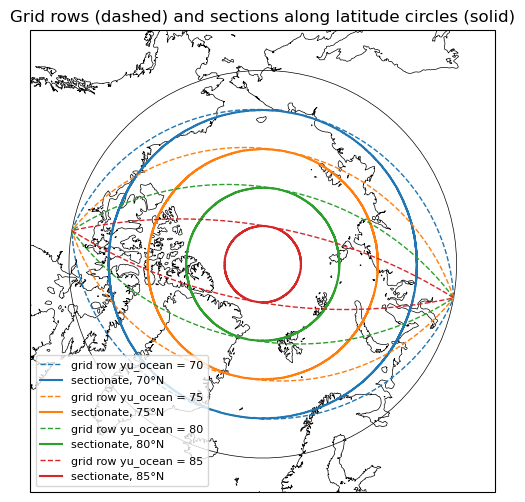

In [10]:
def section_along_latitude(lat, dlon=5):
    """Staircase of cell corners that follows the latitude circle `lat`."""
    lons = np.arange(0, 360 + dlon, dlon)
    lats = np.full(lons.shape, lat, dtype=float)
    i_c, j_c, lons_c, lats_c = sectionate.grid_section(grid, lons, lats, topology="MOM-tripolar")
    return i_c, j_c, lons_c, lats_c

fig = plt.figure(figsize=(6, 6))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 60, 90], crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.5)
ax.gridlines(ylocs=[65, 70, 75, 80, 85], xlocs=[], color='k', linewidth=0.5)
for k, lat in enumerate([70, 75, 80, 85]):
    row_coords = grid_coords.sel(yu_ocean=lat, method="nearest")
    ax.plot(row_coords.geolon_c, row_coords.geolat_c, color=f'C{k}', linestyle='--', linewidth=1,
            transform=ccrs.Geodetic(), label=f'grid row yu_ocean = {float(row_coords.yu_ocean):.0f}')
    i_c, j_c, lons_c, lats_c = section_along_latitude(lat)
    ax.plot(lons_c, lats_c, color=f'C{k}', transform=ccrs.Geodetic(), label=f'sectionate, {lat}°N')
ax.legend(loc='lower left', fontsize=8)
ax.set_title('Grid rows (dashed) and sections along latitude circles (solid)');

Now the heat transport across a section. `convergent_transport` returns, for each face along the section, the transport through it with a sign: by default, positive into the region enclosed by the section, which for our eastward sections around the globe is the region *south* of the section. So the northward heat transport is minus its sum along the section. (The output is called `conv_mass_transport`, but `sectionate` just sums whatever transports we give it, here heat transports.)

In [11]:
def northward_heat_transport(lat):
    """Northward heat transport (PW) across the latitude circle `lat`."""
    i_c, j_c, _, _ = section_along_latitude(lat)
    transport = sectionate.convergent_transport(grid, i_c, j_c,
                                                utr="temp_xflux_adv_int_z", vtr="temp_yflux_adv_int_z",
                                                layer=None, interface=None)
    northward = -transport.conv_mass_transport.sum("sect") / 1e15
    northward.attrs = {"long_name": "northward heat transport", "units": "PW"}
    return northward

As a check, south of 65$^\circ$N, where the grid rows are latitude circles, the section along a row should give the same heat transport as summing `temp_yflux_adv_int_z` along that row. (We don't need this check, or the one in the next section, to compute the heat transport: they are here to make sure the transports from `sectionate` are consistent, and to help us understand what `sectionate` does.) The first call to `sectionate` takes a few minutes longer than the others, because it compiles some of its functions.

In [12]:
row = ds_adv.yu_ocean.sel(yu_ocean=62, method="nearest")
MHT_row_sectionate = northward_heat_transport(float(row))

difference = np.abs(MHT_row_sectionate - MHT_method_1.sel(yu_ocean=row))
print(f"row yu_ocean = {float(row):.2f}: {float(MHT_row_sectionate):.4f} PW from sectionate, "
      f"difference from the sum along the row: {float(difference):.1e} PW")

row yu_ocean = 62.01: 0.3733 PW from sectionate, difference from the sum along the row: 8.0e-08 PW


They agree to round-off. Now we compute the heat transport across latitude circles north of 65$^\circ$N, every 1$^\circ$ from 66$^\circ$N to 89$^\circ$N. On this 0.1$^\circ$ grid this takes about 20 minutes, almost all of it in `grid_section`.

In [13]:
%%time
lats_north = np.arange(66, 89.1, 1)

MHT_north = xr.concat([northward_heat_transport(lat) for lat in lats_north],
                      dim=xr.DataArray(lats_north, dims="lat", name="lat")).load()

CPU times: user 24min 59s, sys: 8min 12s, total: 33min 11s
Wall time: 22min 7s


#### Checking the heat transports

There is an independent way to get the heat transport across a latitude circle, which makes a good check. As with the check above, we don't need it to compute the heat transport. Whatever heat flows across the circle into the polar cap north of it flows into the grid cells of the cap. If we add up the horizontal convergence of `temp_xflux_adv_int_z` and `temp_yflux_adv_int_z` over all the cells whose centres lie north of the circle, the flux through every face shared by two of these cells cancels, and only the flux across the boundary of the cap remains (this is the divergence theorem). That boundary is also a staircase that follows the latitude circle, though not exactly the same one as `sectionate`'s.

In [14]:
# Heat fluxes in PW; float64 avoids round-off in the sums over many cells.
tx = heat_fluxes.temp_xflux_adv_int_z.values.astype("float64") / 1e15
ty = heat_fluxes.temp_yflux_adv_int_z.values.astype("float64") / 1e15

# On the non-symmetric grid, tx[:, i] is on the east face of cell i and tx[:, i-1] on its west face
# (periodic in i); ty[j, :] is on the north face of the cells in row j and ty[j-1, :] on their south face.
# We drop the first row, whose south faces we don't have.
convergence = (np.roll(tx, 1, axis=1) - tx)[1:] + (ty[:-1] - ty[1:])
geolat = heat_fluxes.geolat_t.values[1:]

print("latitude   northward heat transport (PW)")
print("           convergence   sectionate   along the grid row")
for lat in [70, 75, 80, 85, 89]:
    from_convergence = convergence[geolat > lat].sum()
    from_sectionate = float(MHT_north.sel(lat=lat))
    along_row = float(MHT_method_1.sel(yu_ocean=lat, method="nearest"))
    print(f"{lat:6.1f}       {from_convergence:+7.4f}      {from_sectionate:+7.4f}      {along_row:+7.4f}")

latitude   northward heat transport (PW)
           convergence   sectionate   along the grid row
  70.0       +0.2074      +0.2073      +0.2177
  75.0       +0.0932      +0.0930      +0.1248
  80.0       +0.0161      +0.0161      +0.0402
  85.0       +0.0000      +0.0000      +0.0069
  89.0       +0.0000      +0.0000      +0.0006


The convergence and `sectionate` agree to within about 0.0002 PW at every latitude, all the way to the pole; the small differences come from the slightly different staircases. The sum along the grid row with the same label is larger: a grid row labelled, e.g., 80$^\circ$N dips down to 65$^\circ$N near the grid's poles, so the region north of it is larger, and includes heat that has crossed 80$^\circ$N but not the row. North of about 80$^\circ$N the latitude circles cross the line along which the tripolar grid folds onto itself, so this also checks that `sectionate` joins the two sides of the fold correctly.

We now combine the zonal sums along the grid rows south of 65$^\circ$N, which are exact there, with the `sectionate` heat transport north of 65$^\circ$N:

In [15]:
MHT_method_1_lat = xr.concat([MHT_method_1.sel(yu_ocean=slice(None, 65)).rename(yu_ocean="lat"), MHT_north], dim="lat")
MHT_method_1_lat.lat.attrs = {"long_name": "latitude", "units": "degrees_north"}
MHT_method_1_lat.attrs = {"long_name": "northward heat transport", "units": "PW"}

## Method 2: Using surface and frazil heat fluxes 

First, we load the surface heat flux and grid metrics:

In [16]:
ds_sfc = catalog[experiment].search(variable = ['net_sfc_heating'], frequency='1mon').to_dask(xarray_open_kwargs={"decode_timedelta": True})
ds_sfc = ds_sfc['net_sfc_heating'].sel(time=slice(start_time, end_time))
ds_sfc

<xarray.DataArray 'net_sfc_heating' (time: 72, yt_ocean: 2700, xt_ocean: 3600)> Size: 3GB
dask.array<getitem, shape=(72, 2700, 3600), dtype=float32, chunksize=(3, 2700, 3600), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) datetime64[ns] 576B 2000-01-16T12:00:00 ... 2005-12-16T1...
  * yt_ocean  (yt_ocean) float64 22kB -81.11 -81.07 -81.02 ... 89.89 89.94 89.98
  * xt_ocean  (xt_ocean) float64 29kB -279.9 -279.8 -279.7 ... 79.75 79.85 79.95
Attributes:
    long_name:      surface ocean heat flux coming through coupler and mass t...
    units:          Watts/m^2
    valid_range:    [-10000.  10000.]
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT

In [17]:
ds_frz = catalog[experiment].search(variable = ['frazil_3d_int_z'], frequency='1mon').to_dask(xarray_open_kwargs={"decode_timedelta": True})
ds_frz = ds_frz['frazil_3d_int_z'].sel(time=slice(start_time, end_time))
ds_frz

<xarray.DataArray 'frazil_3d_int_z' (time: 72, yt_ocean: 2700, xt_ocean: 3600)> Size: 3GB
dask.array<getitem, shape=(72, 2700, 3600), dtype=float32, chunksize=(3, 2700, 3600), chunktype=numpy.ndarray>
Coordinates:
  * time      (time) datetime64[ns] 576B 2000-01-16T12:00:00 ... 2005-12-16T1...
  * yt_ocean  (yt_ocean) float64 22kB -81.11 -81.07 -81.02 ... 89.89 89.94 89.98
  * xt_ocean  (xt_ocean) float64 29kB -279.9 -279.8 -279.7 ... 79.75 79.85 79.95
Attributes:
    long_name:      Vertical sum of ocn frazil heat flux over time step
    units:          W/m^2
    valid_range:    [-1.e+10  1.e+10]
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT

Add the heat fluxes and take the `time` mean:

In [18]:
shflux = (ds_sfc + ds_frz).mean('time').load()

In [19]:
# Get the relevant grid_info
area = catalog[experiment].search(variable='area_t', frequency='fx').to_dask()['area_t']
geolat_t = catalog[experiment].search(variable='geolat_t', frequency='fx').to_dask()['geolat_t']
geolon_t = catalog[experiment].search(variable='geolon_t', frequency='fx').to_dask()['geolon_t']

In [20]:
# Add geolat_t and geolon_t coords
area = area.assign_coords({'geolon_t': geolon_t, 'geolat_t': geolat_t})
shflux = shflux.assign_coords({'geolon_t': geolon_t, 'geolat_t': geolat_t})

Now calculate Meridional Heat Flux (MHF). This is done by calculating the total heat flux as the heat flux times the area, and then integrating in latitude space such that for each latitude:

$$
\mathrm{MHF}(y) = \int_{y_{0}}^{y} (\mathrm{SHFLUX} \times \mathrm{AREA}) \, \mathrm{d}y
$$

In [21]:
# Create left edge for bottom bin
latv_bins = np.hstack(([-90], area['yt_ocean'].values))

MHT = shflux * area
MHT = MHT.groupby_bins('geolat_t', latv_bins)
MHT = MHT.sum()
MHT = MHT.cumsum()
MHT = MHT.rename(geolat_t_bins='yt_ocean')
MHT.coords['yt_ocean'] = area['yt_ocean']

MHT_method_2 = MHT + (MHT.isel(yt_ocean=0) - MHT.isel(yt_ocean=-1)) / 2

# Convert from W to PW
MHT_method_2 = MHT_method_2 / 1e15
MHT_method_2.attrs = {"long_name": "northward heat transport", "units": "PW"}

# Method 2 integrated from the North Pole instead: minus the heat lost through the surface north of each latitude
MHT_method_2_from_north = MHT_method_2 - MHT_method_2.isel(yt_ocean=-1)
MHT_method_2_from_north.attrs = {"long_name": "northward heat transport", "units": "PW"}

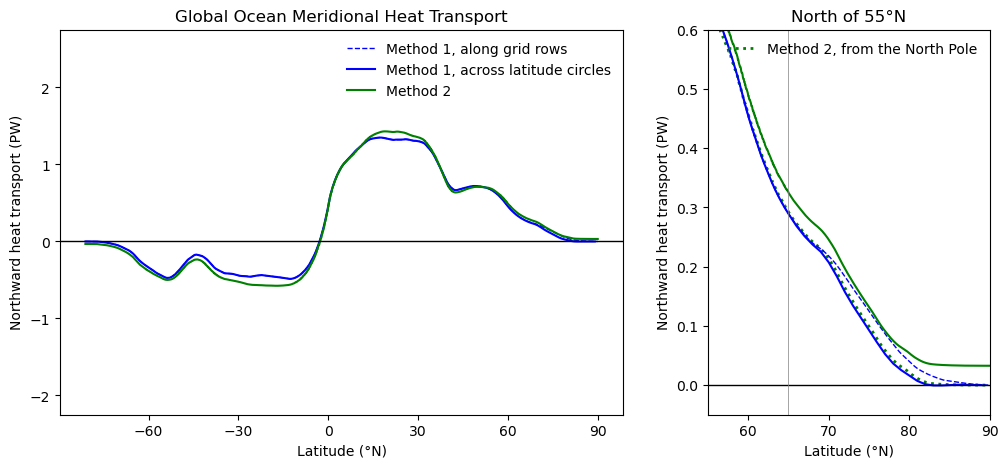

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2, 1]})

from_north, = MHT_method_2_from_north.plot(ax = axs[1], color = 'green', linestyle = ':', linewidth = 2,
                                           label = 'Method 2, from the North Pole')

for ax in axs:
    MHT_method_1.plot(ax = ax, color = 'blue', linestyle = '--', linewidth = 1, label = 'Method 1, along grid rows')
    MHT_method_1_lat.plot(ax = ax, color = 'blue', label = 'Method 1, across latitude circles')
    MHT_method_2.plot(ax = ax, color = 'green', label = 'Method 2')
    ax.axhline(y=0, linewidth=1, color='black')
    ax.set_xlabel('Latitude (°N)')
    ax.set_ylabel('Northward heat transport (PW)')

axs[0].set_xticks(np.arange(-60, 91, 30))
axs[0].set_ylim(-2.25, 2.75)
axs[0].legend(frameon=False, fontsize=10)
axs[0].set_title('Global Ocean Meridional Heat Transport')

axs[1].legend(handles=[from_north], frameon=False, fontsize=10)
axs[1].set_xlim(55, 90)
axs[1].set_ylim(-0.05, 0.6)
axs[1].axvline(x=65, linewidth=0.5, color='grey')
axs[1].set_title('North of 55°N');

South of 65$^\circ$N the two versions of Method 1 are the same. North of 65$^\circ$N, summing along the grid rows overestimates the heat transport across latitude circles, as we saw in the table above.

Method 2 is higher than Method 1 north of about 55$^\circ$N, by about 0.03 PW, and doesn't go to zero at the North Pole, where no heat can cross. Method 2 assumes a steady state, but over these six years the surface heat flux into the ocean doesn't add up to zero over the globe. Method 2 spreads this imbalance by shifting its whole curve (the last step in computing `MHT_method_2`), so that it ends at about +0.03 PW at the North Pole.

In the Arctic, a fairer comparison is Method 2 integrated from the North Pole instead (dotted green in the right panel), i.e., minus the heat lost through the surface north of each latitude. It agrees with the heat transport across latitude circles from `sectionate` to within about 0.007 PW at every latitude, while the sum along the grid rows is up to 0.025 PW higher, around 75$^\circ$N. The small remaining difference comes from what each method leaves out: Method 2 assumes that the heat content north of each latitude doesn't change, and Method 1 includes only the heat transport by the resolved flow.

## Comparison between model output and observations

The following section compares the model's heat transport to observations. These observations are derived using various methods, in particular using surface flux observations a la method 2 (which assumes a steady state).

### Read ERBE Period Ocean and Atmospheric Heat Transport

This data comes (annoyingly) in a text file. The cell below opens and saves latitudes and heat transport into two separate lists: 

In [23]:
# Path to the file containing observations
filename = '/g/data3/ik11/from_hh5_tmp/cosima/observations/original/MHT/obs_vq_am_estimates.txt'

# Create empty variables to store our observations
erbe_MHT = []
erbe_lat = []

# Open data and save it to empty variables above
with open(filename) as f:
    #Open each line from rows 1 to 96
    for line in f.readlines()[1:96]:
        #Separating each line to extract data
        line = line.strip()
        sline = line.split()
        #Extracting latitude and MHT and saving to empty variables
        erbe_lat.append(float(sline[0]))
        erbe_MHT.append(float(sline[3]))

### Read NCEP and ECMWF Oceanic and Atmospheric Transport Products

These datasets are available at https://climatedataguide.ucar.edu/climate-data. We use a climatological mean of surface fluxes or vertically integrated total energy divergence for oceanic and atmospheric transports respectively for the period between February 1985 - April 1989.

This also comes as a text file and again, we will save it into lists. There is also an estimate of the observational error:

In [24]:
#Path to the file containing observations
filename = '/g/data/ik11/observations/ANNUAL_TRANSPORTS_1985_1989.ascii'

#Creating empty variables to store our observations
ncep_g_mht = []
ecwmf_g_mht = []
ncep_g_err = []
ecwmf_g_err = []
ncep_a_mht = []
ecwmf_a_mht = []
ncep_a_err = []
ecwmf_a_err = []
ncep_p_mht = []
ecwmf_p_mht = []
ncep_p_err = []
ecwmf_p_err = []
ncep_i_mht = []
ecwmf_i_mht = []
ncep_i_err = []
ecwmf_i_err = []
ncep_ip_mht = []
ecwmf_ip_mht = []
ncep_ip_err = []
ecwmf_ip_err = []
o_lat = []

#Opening data and saving it to empty variables above
with open(filename) as f:
#Open each line in file (ignoring the first row)
    for line in f.readlines()[1:]:
        #Separating each line to extract data
        line = line.strip()
        sline = line.split()
        #Extracting values and saving to correct variable defined above
        o_lat.append(float(sline[0]) * 0.01)         # T42 latitudes (north to south)
        ncep_g_mht.append(float(sline[4]) * 0.01)    # Residual Ocean Transport - NCEP
        ecwmf_g_mht.append(float(sline[5]) * 0.01)   # Residual Ocean Transport - ECWMF
        ncep_a_mht.append(float(sline[7]) * 0.01)    # Atlantic Ocean Basin Transport - NCEP
        ncep_p_mht.append(float(sline[8]) * 0.01)    # Pacific Ocean Basin Transport - NCEP
        ncep_i_mht.append(float(sline[9]) * 0.01)    # Indian Ocean Basin Transport - NCEP
        ncep_g_err.append(float(sline[10]) * 0.01)   # Error Bars for NCEP Total Transports
        ncep_a_err.append(float(sline[11]) * 0.01)   # Error Bars for NCEP Atlantic Transports 
        ncep_p_err.append(float(sline[12]) * 0.01)   # Error Bars for NCEP Pacific Transports 
        ncep_i_err.append(float(sline[13]) * 0.01)   # Error Bars for NCEP Indian Transports 
        ecwmf_a_mht.append(float(sline[15]) * 0.01)  # Atlantic Ocean Basin Transport - ECWMF
        ecwmf_p_mht.append(float(sline[16]) * 0.01)  # Pacific Ocean Basin Transport - ECWMF
        ecwmf_i_mht.append(float(sline[17]) * 0.01)  # Indian Ocean Basin Transport - ECWMF
        ecwmf_g_err.append(float(sline[18]) * 0.01)  # Error Bars for ECWMF Total Transports
        ecwmf_a_err.append(float(sline[19]) * 0.01)  # Error Bars for NCEP Atlantic Transports
        ecwmf_p_err.append(float(sline[20]) * 0.01)  # Error Bars for NCEP Pacific Transports
        ecwmf_i_err.append(float(sline[21]) * 0.01)  # Error Bars for NCEP Indian Transports

#Calculating MHT
ncep_ip_mht  = [a+b for a, b in zip(ncep_p_mht,ncep_i_mht)]
ecwmf_ip_mht = [a+b for a, b in zip(ecwmf_p_mht,ecwmf_i_mht)]
ncep_ip_err  = [max(a, b) for a, b in zip(ncep_p_err, ncep_i_err)]
ecwmf_ip_err = [max(a, b) for a, b in zip(ecwmf_p_err, ecwmf_i_err)]

## Plotting model outputs against observations

We plot the global meridional heat transport as calculated from model outputs (blue line) and observations.

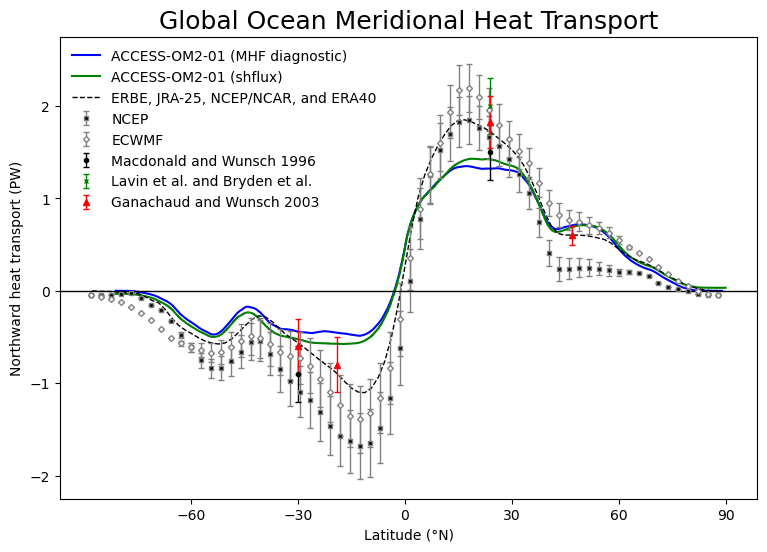

In [25]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(1, 1, 1)

#Plotting MHT from model outputs
MHT_method_1_lat.plot(ax = ax, color = "blue", label = "ACCESS-OM2-01 (MHF diagnostic)")
MHT_method_2.plot(ax = ax, color = "green", label = "ACCESS-OM2-01 (shflux)")

#Adding observations and error bars for observations
ax.plot(erbe_lat, erbe_MHT, 'k--', linewidth=1, label="ERBE, JRA-25, NCEP/NCAR, and ERA40")
plt.errorbar(o_lat[::-1], ncep_g_mht[::-1], yerr=ncep_g_err[::-1], c='gray', fmt='s', 
             markerfacecolor='k', markersize=3, capsize=2, linewidth=1, label="NCEP")
plt.errorbar(o_lat[::-1], ecwmf_g_mht[::-1], yerr=ecwmf_g_err[::-1], c='gray', fmt='D', 
             markerfacecolor='white', markersize=3, capsize=2, linewidth=1, label="ECWMF")
plt.errorbar( 24,  1.5, yerr=0.3, fmt='o', c='black', markersize=3, capsize=2, linewidth=1,
             label="Macdonald and Wunsch 1996")
plt.errorbar(-30, -0.9, yerr=0.3, fmt='o', c='black', markersize=3, capsize=2, linewidth=1)
plt.errorbar( 24,  2.0, yerr=0.3, fmt='x', c='green', markersize=3, capsize=2, linewidth=1,
             label="Lavin et al. and Bryden et al.")
plt.errorbar( 24,  1.83, yerr=0.28, fmt='^', c='red', markersize=4, capsize=2, linewidth=1,
             label="Ganachaud and Wunsch 2003")
plt.errorbar(-30, -0.6, yerr=0.3, fmt='^', c='red', markersize=4, capsize=2, linewidth=1)
plt.errorbar(-19, -0.8, yerr=0.3, fmt='^', c='red', markersize=4, capsize=2, linewidth=1)
plt.errorbar( 47,  0.6, yerr=0.1, fmt='^', c='red', markersize=4, capsize=2, linewidth=1)

# add legend
plt.legend(frameon=False, fontsize=10)
plt.axhline(y=0, linewidth=1, color='black')

# limits along the y axis
plt.ylim(-2.25, 2.75)

# add titles and labels
plt.title('Global Ocean Meridional Heat Transport', fontsize=18)
plt.xticks(np.arange(-60, 91, 30))
plt.xlabel('Latitude (°N)')
plt.ylabel('Northward heat transport (PW)');

In [26]:
client.close()